# LAB 09 — Bias, Variance and Imbalanced Data

## Student Information
**Name:** Muhammad Umar  
**Student ID:** 023-24-0260 *(please verify before submission)*  
**Section:** H  
**GitHub:** [Add your GitHub profile/link]  
**Kaggle:** [Add your Kaggle profile/link]  
**Dataset:** Stroke Prediction Dataset (Kaggle)  
**Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

> **Before running:** Keep `healthcare-dataset-stroke-data.csv` in the same folder as this notebook, or update `DATA_PATH` below. Install dependencies once with `pip install pandas numpy matplotlib scikit-learn imbalanced-learn`. Run all cells from top to bottom.

## Lab Overview
This notebook follows Parts 0–6 of the supplied lab manual. The target is `stroke` (1 = stroke, 0 = no stroke). The random seed is fixed at 42. Imputation, scaling, resampling, and threshold selection are learned from training data only, except in Part 4 Task 4.2 where the deliberately incorrect leakage workflow is demonstrated.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    validation_curve, learning_curve, cross_val_predict
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve
)
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
DATA_PATH = "healthcare-dataset-stroke-data.csv"

## Part 0 — Setup and the Data

Load and inspect the dataset, remove the ID column and the single-row `Other` gender category, encode categorical features, then create a stratified 80/20 split. The median imputer and StandardScaler are fitted using training data only.

In [2]:
# Load the dataset. If the file has a different name, update DATA_PATH.
if not os.path.exists(DATA_PATH):
    alternatives = [
        "healthcare-dataset-stroke-data_1.csv",
        "/mnt/data/healthcare-dataset-stroke-data.csv",
        "/mnt/data/healthcare-dataset-stroke-data_1.csv"
    ]
    found = [name for name in alternatives if os.path.exists(name)]
    if found:
        DATA_PATH = found[0]
    else:
        raise FileNotFoundError(
            "Place healthcare-dataset-stroke-data.csv beside this notebook "
            "or update DATA_PATH to the CSV file location."
        )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\\nMissing values:")
print(df.isna().sum())
print("\\nGender counts:")
print(df["gender"].value_counts())
print("\\nStroke counts:")
print(df["stroke"].value_counts())
print("\\nStroke percentages:")
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (5110, 12)
\nMissing values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
\nGender counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
\nStroke counts:
stroke
0    4861
1     249
Name: count, dtype: int64
\nStroke percentages:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


**Part 0 — Question (a)**

The target is imbalanced when the no-stroke class is much larger than the stroke class. `stratify=y` keeps approximately the same class proportions in both training and test sets. Without stratification, the small number of stroke cases could be distributed unevenly, leaving too few positive test examples for a dependable evaluation.

In [3]:
# Remove the identifier and the gender category with only one row.
data = df.drop(columns=["id"]).copy()
data = data[data["gender"] != "Other"].copy()

X = data.drop(columns=["stroke"])
y = data["stroke"].astype(int)

# One-hot encode text columns.
X = pd.get_dummies(X, drop_first=False, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Learn numeric medians from training data only.
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Scaled copies for Logistic Regression.
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print("Cleaned feature shape:", X.shape)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Stroke cases in training:", int(y_train.sum()))
print("Stroke cases in test:", int(y_test.sum()))
print("Training class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Cleaned feature shape: (5109, 20)
Training rows: 4087 | Test rows: 1022
Stroke cases in training: 199
Stroke cases in test: 50
Training class percentages:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


## Part 1 — The Accuracy Trap

The majority-class baseline always predicts no stroke. Logistic Regression is evaluated using accuracy, precision, recall, F1, ROC AUC, and average precision (PR AUC). Accuracy alone is not enough for this imbalanced medical dataset.

Majority baseline accuracy: 0.9511
\nLogistic Regression metrics:


,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Logistic Regression,0.9521,1.0,0.02,0.0392,0.8393,0.2696


Confusion matrix (rows = actual, columns = predicted):
[[972   0]
 [ 49   1]]


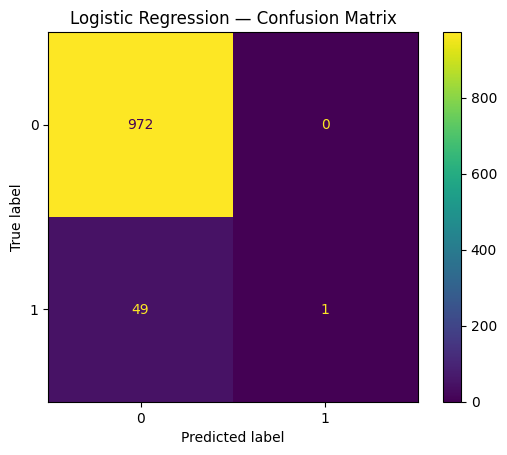

In [4]:
def get_metrics(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    prob = model.predict_proba(Xte)[:, 1]
    return {
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred, zero_division=0),
        "F1": f1_score(yte, pred, zero_division=0),
        "ROC AUC": roc_auc_score(yte, prob),
        "PR AUC": average_precision_score(yte, prob)
    }

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_accuracy = accuracy_score(y_test, dummy_pred)

log_model = LogisticRegression(max_iter=2000, random_state=SEED)
part1_metrics = get_metrics(
    log_model, X_train_scaled, y_train, X_test_scaled, y_test
)

print("Majority baseline accuracy:", round(dummy_accuracy, 4))
print("\\nLogistic Regression metrics:")
display(pd.DataFrame([part1_metrics], index=["Logistic Regression"]).round(4))

log_pred = log_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, log_pred)
print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

**Part 1 — Questions (a) and (b)**

Compare the baseline accuracy printed above with Logistic Regression accuracy. A high baseline accuracy can simply mean that the model predicts the majority class for almost everyone; it may still miss most stroke patients. A false negative is a patient who actually had a stroke but is predicted as no stroke. For screening, recall is especially important because it measures the fraction of actual stroke cases detected. Precision, F1, ROC AUC, PR AUC, and the confusion matrix should be considered alongside accuracy.

## Part 2 — Underfitting, Overfitting, Bias and Variance

### Task 2.1 — Validation curve
The decision tree is evaluated for depths 1–15 and unlimited depth. ROC AUC is used for both training and stratified five-fold cross-validation.

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,max_depth,Train ROC AUC,CV ROC AUC
0,1,0.7171,0.7317
1,2,0.8208,0.8168
2,3,0.8375,0.8161
3,4,0.8580,0.8180
4,5,0.8758,0.7904
5,6,0.9021,0.7503
6,7,0.9286,0.7382
7,8,0.9490,0.7215
8,9,0.9674,0.6819
9,10,0.9817,0.6444


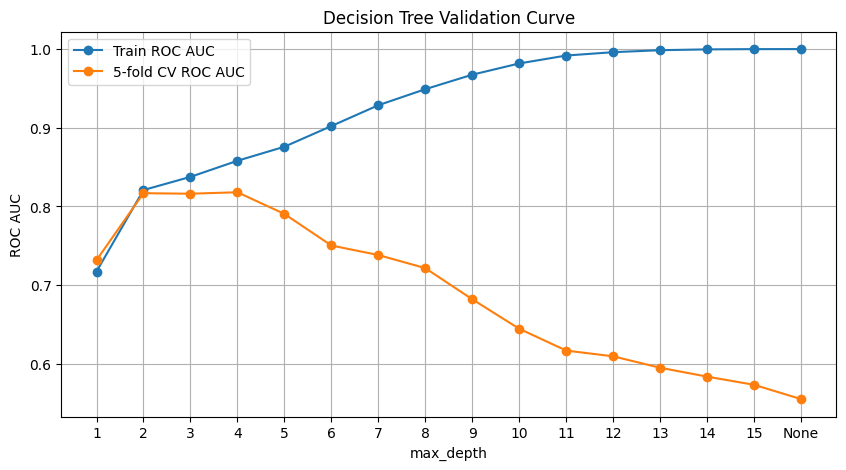

Best depth by CV ROC AUC: 4


In [5]:
depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train_auc = []
cv_auc = []
for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    tree.fit(X_train, y_train)
    train_auc.append(roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]))
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=depth, random_state=SEED),
        X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    cv_auc.append(scores.mean())

validation_results = pd.DataFrame({
    "max_depth": [str(d) for d in depths],
    "Train ROC AUC": train_auc,
    "CV ROC AUC": cv_auc
})
display(validation_results.round(4))

plt.figure(figsize=(10, 5))
x_labels = [str(d) for d in depths]
plt.plot(x_labels, train_auc, marker="o", label="Train ROC AUC")
plt.plot(x_labels, cv_auc, marker="o", label="5-fold CV ROC AUC")
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree Validation Curve")
plt.legend()
plt.grid(True)
plt.show()

best_depth = depths[int(np.argmax(cv_auc))]
print("Best depth by CV ROC AUC:", best_depth)

**Task 2.1 — Interpretation**

Use the table and plot above to identify the depth with the highest cross-validation AUC. Very shallow trees with low training and CV scores indicate underfitting (high bias). A large gap between a very high training score and a lower CV score indicates overfitting (high variance). The best depth is the one with the highest CV AUC, not necessarily the highest training AUC.

### Task 2.2 — Learning curves
Learning curves compare a shallow tree (`max_depth=1`) and an unrestricted tree as the number of training rows increases.

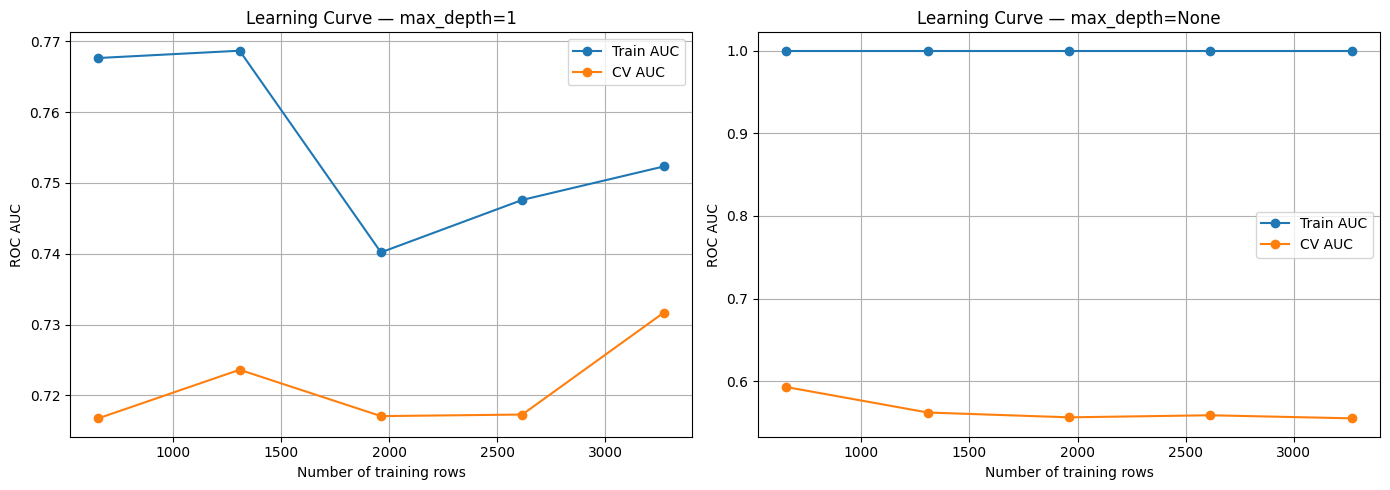

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
learning_outputs = {}

for ax, depth, title in zip(
    axes, [1, None], ["Learning Curve — max_depth=1", "Learning Curve — max_depth=None"]
):
    sizes, train_scores, valid_scores = learning_curve(
        DecisionTreeClassifier(max_depth=depth, random_state=SEED),
        X_train, y_train,
        train_sizes=np.linspace(0.2, 1.0, 5),
        cv=cv, scoring="roc_auc", n_jobs=-1
    )
    train_mean = train_scores.mean(axis=1)
    valid_mean = valid_scores.mean(axis=1)
    learning_outputs[str(depth)] = (sizes, train_mean, valid_mean)
    ax.plot(sizes, train_mean, marker="o", label="Train AUC")
    ax.plot(sizes, valid_mean, marker="o", label="CV AUC")
    ax.set_xlabel("Number of training rows")
    ax.set_ylabel("ROC AUC")
    ax.set_title(title)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

**Task 2.2 — Interpretation**

A high-bias model has low training and validation scores that remain close together; adding more rows may not solve a model that is too simple. A high-variance model has a high training score and a noticeably lower validation score. More representative training data can sometimes reduce that gap, although model complexity may also need to be controlled.

### Task 2.3 — Measure variance directly
For each depth (1, 3 and None), 40 bootstrap samples are drawn from the training rows. Each tree predicts probabilities for the same untouched test patients. We calculate the average per-patient prediction variance, mean individual-tree test AUC, and AUC of the averaged probabilities.

In [7]:
rng = np.random.default_rng(SEED)
variance_rows = []

for depth in [1, 3, None]:
    all_probs = []
    individual_aucs = []
    for _ in range(40):
        idx = rng.choice(len(X_train), size=len(X_train), replace=True)
        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]
        tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
        tree.fit(X_boot, y_boot)
        prob = tree.predict_proba(X_test)[:, 1]
        all_probs.append(prob)
        individual_aucs.append(roc_auc_score(y_test, prob))

    all_probs = np.asarray(all_probs)
    mean_probs = all_probs.mean(axis=0)
    variance_rows.append({
        "max_depth": str(depth),
        "Mean prediction variance": all_probs.var(axis=0).mean(),
        "Mean individual-tree ROC AUC": np.mean(individual_aucs),
        "AUC of averaged prediction": roc_auc_score(y_test, mean_probs)
    })

variance_table = pd.DataFrame(variance_rows)
display(variance_table.round(5))

,max_depth,Mean prediction variance,Mean individual-tree ROC AUC,AUC of averaged prediction
0,1,0.00068,0.76234,0.81317
1,3,0.00171,0.79626,0.83361
2,None,0.04202,0.55420,0.77010


**Part 2 — Questions (a)–(d)**

(a) Use the validation curve to identify underfitting and overfitting depths. Quote the training and CV AUC values from the table for one example in each region.

(b) On learning curves, high bias appears when both curves are low and close. High variance appears when training AUC is much higher than CV AUC. Additional data may help high variance, but usually does not fix a model that is too simple.

(c) Compare the measured variance across depths in the variance table. Deeper trees can react more strongly to changes in sampled training rows. Averaging predictions can be more stable than relying on one tree; this is the central idea behind Random Forest.

(d) The bias–variance trade-off is the balance between a model being too simple to learn useful patterns and being so complex that it learns details specific to its training sample. Depth 1 is highly constrained, depth 3 is more flexible, and unlimited depth has the greatest capacity to overfit. Confirm the exact behaviour using your measured results above.

## Part 3 — ROC, AUC, Precision-Recall and Thresholds

### Task 3.1 — Compare models with curves
Train Logistic Regression, a depth-3 Decision Tree, and a Random Forest on the original training data.

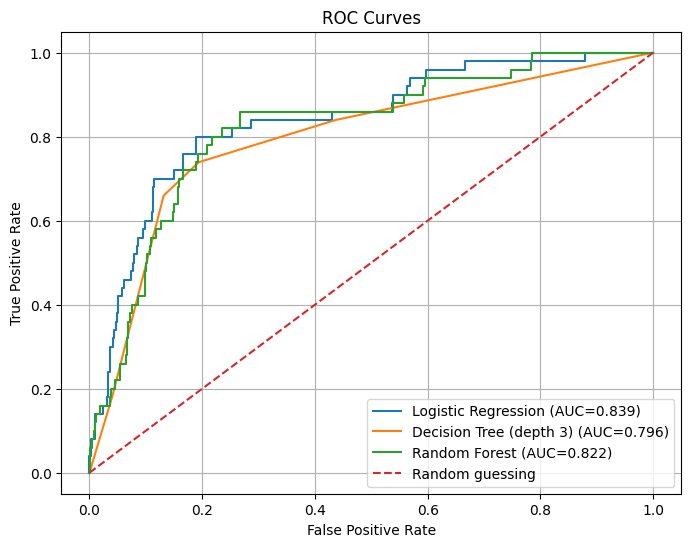

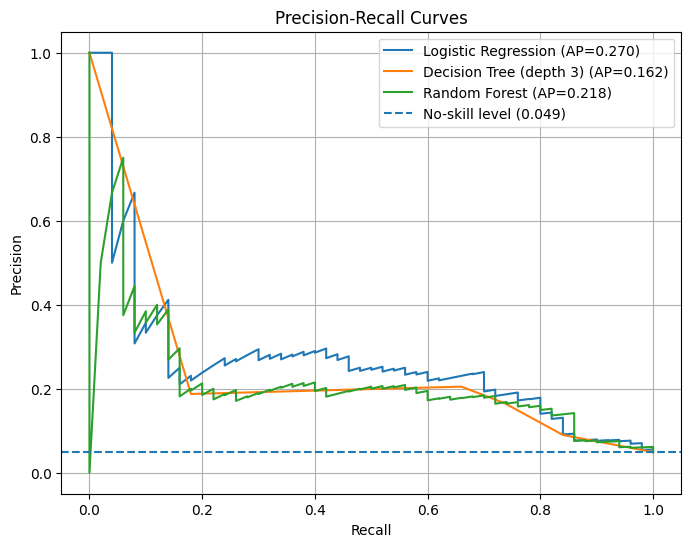

,ROC AUC,PR AUC
Logistic Regression,0.8393,0.2696
Decision Tree (depth 3),0.7956,0.1621
Random Forest,0.8215,0.2183


In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Decision Tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1
    )
}
model_probabilities = {}
model_curve_metrics = {}

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        prob = model.predict_proba(X_test)[:, 1]
    model_probabilities[name] = prob
    model_curve_metrics[name] = {
        "ROC AUC": roc_auc_score(y_test, prob),
        "PR AUC": average_precision_score(y_test, prob)
    }

plt.figure(figsize=(8, 6))
for name, prob in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 6))
stroke_rate = y_test.mean()
for name, prob in model_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    plt.plot(recall, precision, label=f"{name} (AP={average_precision_score(y_test, prob):.3f})")
plt.axhline(stroke_rate, linestyle="--", label=f"No-skill level ({stroke_rate:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(True)
plt.show()

display(pd.DataFrame(model_curve_metrics).T.round(4))

**Task 3.1 — Interpretation**

The ROC curve shows the trade-off between true-positive rate and false-positive rate across thresholds. The Precision–Recall curve focuses on detecting the rare positive class. Its no-skill reference is the stroke prevalence in the test set. For a strongly imbalanced dataset, PR AUC is often more informative about positive-class performance than ROC AUC.

### Task 3.2 — Choose a decision threshold
Out-of-fold probabilities are generated using training data only. We select the highest threshold whose training out-of-fold recall is at least 0.80, then apply it once to the untouched test probabilities.

In [9]:
lr_cv = LogisticRegression(max_iter=2000, random_state=SEED)
oof_prob = cross_val_predict(
    lr_cv, X_train_scaled, y_train, cv=cv,
    method="predict_proba", n_jobs=-1
)[:, 1]

oof_precision, oof_recall, oof_thresholds = precision_recall_curve(y_train, oof_prob)
eligible = np.where(oof_recall[:-1] >= 0.80)[0]
if len(eligible) == 0:
    chosen_threshold = 0.0
else:
    chosen_threshold = float(oof_thresholds[eligible].max())

lr_final = LogisticRegression(max_iter=2000, random_state=SEED)
lr_final.fit(X_train_scaled, y_train)
test_lr_prob = lr_final.predict_proba(X_test_scaled)[:, 1]
threshold_pred = (test_lr_prob >= chosen_threshold).astype(int)

threshold_cm = confusion_matrix(y_test, threshold_pred)
flagged = int(threshold_pred.sum())
false_alarms = int(threshold_cm[0, 1])

print("Selected threshold from training OOF predictions:", round(chosen_threshold, 5))
print("Test recall:", round(recall_score(y_test, threshold_pred, zero_division=0), 4))
print("Test precision:", round(precision_score(y_test, threshold_pred, zero_division=0), 4))
print("Confusion matrix:")
print(threshold_cm)
print("Patients flagged:", flagged)
print("False alarms:", false_alarms)

Selected threshold from training OOF predictions: 0.05068
Test recall: 0.82
Test precision: 0.1344
Confusion matrix:
[[708 264]
 [  9  41]]
Patients flagged: 305
False alarms: 264


**Part 3 — Questions (a)–(c)**

(a) ROC AUC evaluates how well a model ranks positive cases above negative cases across all possible thresholds. A model can have a good AUC but low recall at the default 0.5 threshold because AUC is not the performance at one fixed threshold. The 0.5 value is only one possible cutoff.

(b) The Precision–Recall curve is especially useful here because stroke is rare; its no-skill line is the low stroke prevalence. ROC AUC can look strong even when precision for the rare class is modest.

(c) Lowering the threshold to achieve higher recall generally flags more patients. The price is more false alarms and lower precision, which can lead to unnecessary follow-up tests and workload. Missing a stroke case can be serious, so a hospital may accept some extra false alarms, but the decision should involve clinicians and available screening capacity.

## Part 4 — Undersampling, Oversampling and SMOTE

### Task 4.1 — Compare the methods
Resampling is applied to the training partition only. Logistic Regression uses scaled features; Random Forest uses the original imputed features. The test set remains untouched.

In [10]:
def resample_data(method, Xtr, ytr):
    if method == "No resampling":
        return Xtr.copy(), ytr.copy()
    if method == "class_weight='balanced'":
        return Xtr.copy(), ytr.copy()
    if method == "Random undersampling":
        sampler = RandomUnderSampler(random_state=SEED)
    elif method == "Random oversampling":
        sampler = RandomOverSampler(random_state=SEED)
    elif method == "SMOTE":
        sampler = SMOTE(random_state=SEED)
    else:
        raise ValueError("Unknown resampling method")
    return sampler.fit_resample(Xtr, ytr)

methods = [
    "No resampling", "class_weight='balanced'",
    "Random undersampling", "Random oversampling", "SMOTE"
]
part4_rows = []

for model_name in ["Logistic Regression", "Random Forest"]:
    for method in methods:
        if model_name == "Logistic Regression":
            Xtr, Xte = X_train_scaled, X_test_scaled
            base_model = LogisticRegression(max_iter=2000, random_state=SEED)
        else:
            Xtr, Xte = X_train, X_test
            base_model = RandomForestClassifier(
                n_estimators=200, min_samples_leaf=5,
                random_state=SEED, n_jobs=-1
            )

        X_res, y_res = resample_data(method, Xtr, y_train)
        if method == "class_weight='balanced'":
            if model_name == "Logistic Regression":
                model = LogisticRegression(
                    max_iter=2000, random_state=SEED, class_weight="balanced"
                )
            else:
                model = RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5,
                    random_state=SEED, n_jobs=-1, class_weight="balanced"
                )
        else:
            model = base_model

        model.fit(X_res, y_res)
        prob = model.predict_proba(Xte)[:, 1]
        pred = (prob >= 0.5).astype(int)
        part4_rows.append({
            "Model": model_name,
            "Method": method,
            "Training rows": len(X_res),
            "Stroke rows in training": int(np.sum(y_res)),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, prob),
            "PR AUC": average_precision_score(y_test, prob)
        })

part4_table = pd.DataFrame(part4_rows)
display(part4_table.round(4))

,Model,Method,Training rows,Stroke rows in training,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,No resampling,4087,199,1.0000,0.02,0.0392,0.8393,0.2696
1,Logistic Regression,class_weight='balanced',4087,199,0.1347,0.80,0.2305,0.8396,0.2596
2,Logistic Regression,Random undersampling,398,199,0.1246,0.82,0.2164,0.8350,0.2333
3,Logistic Regression,Random oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2591
4,Logistic Regression,SMOTE,7776,3888,0.1347,0.80,0.2305,0.8407,0.2957
5,Random Forest,No resampling,4087,199,0.0000,0.00,0.0000,0.8215,0.2183
6,Random Forest,class_weight='balanced',4087,199,0.1667,0.20,0.1818,0.8061,0.2045
7,Random Forest,Random undersampling,398,199,0.1032,0.84,0.1838,0.8132,0.1972
8,Random Forest,Random oversampling,7776,3888,0.1412,0.24,0.1778,0.8023,0.1837
9,Random Forest,SMOTE,7776,3888,0.6667,0.04,0.0755,0.8046,0.2424


**Task 4.1 — Interpretation**

Compare precision, recall, F1, ROC AUC and PR AUC for each model and resampling method. Resampling changes the training distribution, and often changes the decision behaviour (especially recall and precision); it does not change the untouched test distribution. Class weighting changes the model's training penalty without adding or deleting rows. Choose using the medical objective and the precision–recall trade-off, not accuracy alone.

### Task 4.2 — The classic mistake (intentional leakage demonstration)
This cell deliberately applies SMOTE before splitting the full dataset. It is an incorrect workflow included only to demonstrate leakage. Do not use this result as a valid estimate of real-world performance.

In [11]:
# Deliberately WRONG: SMOTE is applied before train/test split.
X_all_filled = pd.DataFrame(imputer.transform(X), columns=X.columns, index=X.index)
X_all_res, y_all_res = SMOTE(random_state=SEED).fit_resample(X_all_filled, y)
X_wrong_train, X_wrong_test, y_wrong_train, y_wrong_test = train_test_split(
    X_all_res, y_all_res, test_size=0.20,
    stratify=y_all_res, random_state=SEED
)

wrong_rf = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1
)
wrong_rf.fit(X_wrong_train, y_wrong_train)
wrong_prob = wrong_rf.predict_proba(X_wrong_test)[:, 1]
wrong_pred = (wrong_prob >= 0.5).astype(int)

# Correct SMOTE-after-split result, matching the RF/SMOTE row above.
correct_smote_row = part4_table[
    (part4_table["Model"] == "Random Forest") &
    (part4_table["Method"] == "SMOTE")
].iloc[0]

wrong_order_table = pd.DataFrame([
    {
        "Workflow": "Correct: split first, SMOTE train only",
        "Precision": correct_smote_row["Precision"],
        "Recall": correct_smote_row["Recall"],
        "F1": correct_smote_row["F1"],
        "ROC AUC": correct_smote_row["ROC AUC"],
        "PR AUC": correct_smote_row["PR AUC"]
    },
    {
        "Workflow": "Wrong: SMOTE before split (leakage)",
        "Precision": precision_score(y_wrong_test, wrong_pred, zero_division=0),
        "Recall": recall_score(y_wrong_test, wrong_pred, zero_division=0),
        "F1": f1_score(y_wrong_test, wrong_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_wrong_test, wrong_prob),
        "PR AUC": average_precision_score(y_wrong_test, wrong_prob)
    }
])
display(wrong_order_table.round(4))

,Workflow,Precision,Recall,F1,ROC AUC,PR AUC
0,"Correct: split first, SMOTE train only",0.6667,0.0400,0.0755,0.8046,0.2424
1,Wrong: SMOTE before split (leakage),0.9978,0.9506,0.9737,0.9952,0.9960


**Part 4 — Questions (a)–(d)**

(a) Use the Logistic Regression rows to describe how recall and precision move across the methods. ROC AUC measures ranking quality, so it may change less than the threshold-based metrics. Resampling does not guarantee that every metric improves.

(b) Compare the Random Forest rows with Logistic Regression. Their responses can differ because Logistic Regression learns a linear decision boundary, while trees split feature space into regions and can react differently to duplicated or synthetic observations.

(c) The wrong-order result is not trustworthy. SMOTE creates synthetic examples using neighbours; when it is run before splitting, information from examples that later enter the test set can influence synthetic training examples (and vice versa). The correct procedure splits first and resamples only the training data.

(d) Choose the method from your results that offers a useful recall while keeping precision and false alarms manageable. Class weighting is simple because it does not create synthetic rows; SMOTE may help recall but adds complexity and can amplify problematic minority examples. State the method you would actually validate further before clinical use.

## Part 5 — Noisy Data

The test set remains untouched. Noise is added only to the training data. Four models are compared: Logistic Regression, depth-3 Decision Tree, unlimited Decision Tree and Random Forest.

### Task 5.1 — Label noise
A selected fraction of training labels is randomly flipped. Each non-zero noise level is repeated five times; the zero-noise level is run once.

Model,Decision Tree (depth 3),Decision Tree (unlimited),Logistic Regression,Random Forest
Noise fraction,,,,
0.00,0.7956,0.5722,0.8393,0.8215
0.05,0.8084,0.5491,0.8232,0.7764
0.10,0.7928,0.5289,0.8112,0.7757
0.20,0.7499,0.5199,0.8022,0.6971


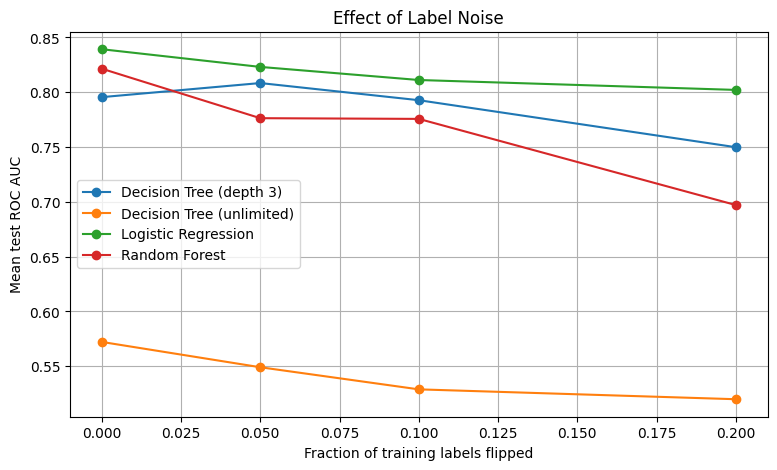

In [12]:
def flip_labels(labels, fraction, random_state):
    rng_local = np.random.default_rng(random_state)
    noisy = np.asarray(labels).copy()
    n_flip = int(round(len(noisy) * fraction))
    chosen = rng_local.choice(len(noisy), size=n_flip, replace=False)
    noisy[chosen] = 1 - noisy[chosen]
    return pd.Series(noisy, index=labels.index)

def build_noise_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
        "Decision Tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
        "Decision Tree (unlimited)": DecisionTreeClassifier(random_state=SEED),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1
        )
    }

label_levels = [0, 0.05, 0.10, 0.20]
label_noise_rows = []

for level in label_levels:
    repeats = 1 if level == 0 else 5
    for repeat in range(repeats):
        noisy_y = flip_labels(y_train, level, SEED + repeat + int(level * 1000))
        for name, model in build_noise_models().items():
            if name == "Logistic Regression":
                model.fit(X_train_scaled, noisy_y)
                prob = model.predict_proba(X_test_scaled)[:, 1]
            else:
                model.fit(X_train, noisy_y)
                prob = model.predict_proba(X_test)[:, 1]
            label_noise_rows.append({
                "Noise fraction": level,
                "Repeat": repeat + 1,
                "Model": name,
                "ROC AUC": roc_auc_score(y_test, prob)
            })

label_noise_raw = pd.DataFrame(label_noise_rows)
label_noise_table = label_noise_raw.groupby(
    ["Noise fraction", "Model"]
)["ROC AUC"].mean().unstack()
display(label_noise_table.round(4))

plt.figure(figsize=(9, 5))
for model_name in label_noise_table.columns:
    plt.plot(label_noise_table.index, label_noise_table[model_name],
             marker="o", label=model_name)
plt.xlabel("Fraction of training labels flipped")
plt.ylabel("Mean test ROC AUC")
plt.title("Effect of Label Noise")
plt.legend()
plt.grid(True)
plt.show()

**Task 5.1 — Interpretation**

Read the values at 0.20 label noise to identify the model with the largest AUC drop and the model that remains most stable. A model with high variance can fit incorrect labels more easily, while a more constrained model may be less sensitive. Use the actual table values to support the comparison.

### Task 5.2 — Feature noise
Gaussian noise is added to the training values of `age`, `avg_glucose_level`, and `bmi`. The noise standard deviation is the original training-column standard deviation multiplied by the noise level. Logistic Regression's scaler is fitted on each noisy training set.

Model,Decision Tree (depth 3),Decision Tree (unlimited),Logistic Regression,Random Forest
Noise level,,,,
0.0,0.7956,0.5722,0.8393,0.8215
0.5,0.7857,0.5305,0.8330,0.8091
1.0,0.7735,0.5237,0.8111,0.7803
2.0,0.7124,0.5218,0.7710,0.7408


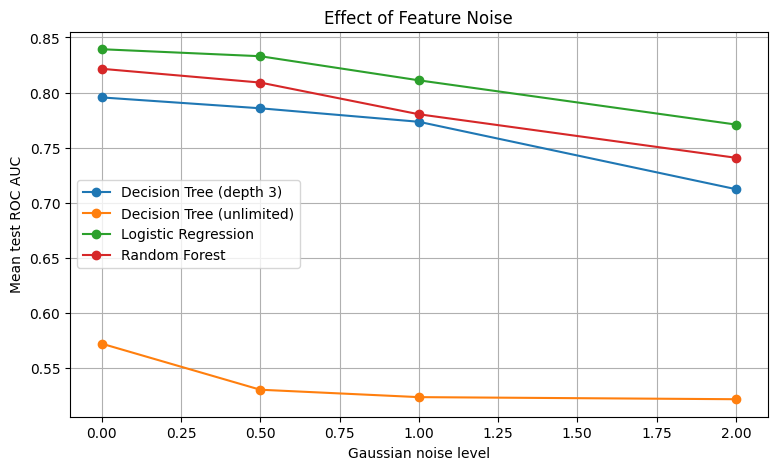

In [13]:
feature_columns = ["age", "avg_glucose_level", "bmi"]
feature_levels = [0, 0.5, 1, 2]
feature_noise_rows = []

for level in feature_levels:
    for repeat in range(5):
        rng_local = np.random.default_rng(SEED + 100 + repeat + int(level * 100))
        X_noisy = X_train.copy()
        for col in feature_columns:
            col_std = X_train[col].std()
            X_noisy[col] = X_noisy[col] + (
                rng_local.normal(0, 1, len(X_noisy)) * col_std * level
            )

        noisy_scaler = StandardScaler()
        X_noisy_scaled = pd.DataFrame(
            noisy_scaler.fit_transform(X_noisy),
            columns=X_noisy.columns, index=X_noisy.index
        )
        X_test_for_lr = pd.DataFrame(
            noisy_scaler.transform(X_test),
            columns=X_test.columns, index=X_test.index
        )

        for name, model in build_noise_models().items():
            if name == "Logistic Regression":
                model.fit(X_noisy_scaled, y_train)
                prob = model.predict_proba(X_test_for_lr)[:, 1]
            else:
                model.fit(X_noisy, y_train)
                prob = model.predict_proba(X_test)[:, 1]
            feature_noise_rows.append({
                "Noise level": level,
                "Repeat": repeat + 1,
                "Model": name,
                "ROC AUC": roc_auc_score(y_test, prob)
            })

feature_noise_raw = pd.DataFrame(feature_noise_rows)
feature_noise_table = feature_noise_raw.groupby(
    ["Noise level", "Model"]
)["ROC AUC"].mean().unstack()
display(feature_noise_table.round(4))

plt.figure(figsize=(9, 5))
for model_name in feature_noise_table.columns:
    plt.plot(feature_noise_table.index, feature_noise_table[model_name],
             marker="o", label=model_name)
plt.xlabel("Gaussian noise level")
plt.ylabel("Mean test ROC AUC")
plt.title("Effect of Feature Noise")
plt.legend()
plt.grid(True)
plt.show()

**Task 5.2 — Interpretation**

Compare each model's AUC as feature noise increases. Feature noise makes selected measurements less reliable, while label noise teaches the model incorrect target relationships. The amount of damage depends on the model and the feature signal; use the plotted results rather than assuming one noise type always causes more harm.

### Task 5.3 — SMOTE and noisy labels
For three independent 10% label-flip draws, compare Logistic Regression and Random Forest with and without SMOTE. SMOTE is applied after label noise is added and only to the training partition.

In [14]:
smote_noise_rows = []

for repeat in range(3):
    noisy_y = flip_labels(y_train, 0.10, SEED + 500 + repeat)

    for name in ["Logistic Regression", "Random Forest"]:
        if name == "Logistic Regression":
            Xtr, Xte = X_train_scaled, X_test_scaled
            make_model = lambda: LogisticRegression(max_iter=2000, random_state=SEED)
        else:
            Xtr, Xte = X_train, X_test
            make_model = lambda: RandomForestClassifier(
                n_estimators=200, min_samples_leaf=5,
                random_state=SEED, n_jobs=-1
            )

        for use_smote in [False, True]:
            if use_smote:
                X_fit, y_fit = SMOTE(random_state=SEED + repeat).fit_resample(Xtr, noisy_y)
                method = "With SMOTE"
            else:
                X_fit, y_fit = Xtr, noisy_y
                method = "Without SMOTE"

            model = make_model()
            model.fit(X_fit, y_fit)
            prob = model.predict_proba(Xte)[:, 1]
            smote_noise_rows.append({
                "Repeat": repeat + 1,
                "Model": name,
                "Method": method,
                "ROC AUC": roc_auc_score(y_test, prob),
                "PR AUC": average_precision_score(y_test, prob)
            })

smote_noise_raw = pd.DataFrame(smote_noise_rows)
smote_noise_table = smote_noise_raw.groupby(
    ["Model", "Method"]
)[["ROC AUC", "PR AUC"]].mean()
display(smote_noise_table.round(4))

ROC AUC  PR AUC
Model               Method                        
Logistic Regression With SMOTE      0.8137  0.2715
                    Without SMOTE   0.8268  0.2830
Random Forest       With SMOTE      0.6897  0.1267
                    Without SMOTE   0.7525  0.1678

**Part 5 — Questions (a)–(c)**

(a) Identify the most damaged and most stable model using the 0.20 label-noise and level-2 feature-noise results. Quote the corresponding AUC values. A deep tree can be sensitive to training-sample changes, while ensembles can reduce variance by averaging many trees.

(b) Compare the drops at the highest label-noise and feature-noise levels. Label noise directly changes the answer the model is learning to predict; feature noise corrupts selected input measurements. Which is worse in this experiment must be decided from the measured AUC drops.

(c) Compare the with-SMOTE and without-SMOTE rows. SMOTE creates new minority examples based on minority neighbours. If some minority labels are wrong, those incorrectly labelled examples can become neighbours and influence synthetic examples, spreading the label error through the resampled training data.

## Part 6 — Final Decision and Conclusion

For a screening use case, this notebook uses the Logistic Regression threshold selected from training-only out-of-fold probabilities in Part 3. The comparison below reports the default threshold (0.5) and the selected threshold on the untouched test set.

In [15]:
default_pred = (test_lr_prob >= 0.5).astype(int)

def final_metrics_row(label, pred):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Approach": label,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "False alarms": int(fp),
        "Missed strokes": int(fn)
    }

final_comparison = pd.DataFrame([
    final_metrics_row("Logistic Regression — threshold 0.5", default_pred),
    final_metrics_row(f"Logistic Regression — threshold {chosen_threshold:.4f}", threshold_pred)
])
display(final_comparison.round(4))

,Approach,Precision,Recall,F1,False alarms,Missed strokes
0,Logistic Regression — threshold 0.5,1.0000,0.02,0.0392,0,49
1,Logistic Regression — threshold 0.0507,0.1344,0.82,0.2310,264,9


### Executive Summary

This lab compared a majority-class baseline and several models on an imbalanced stroke dataset. The selected screening approach is Logistic Regression using a threshold chosen from training-only out-of-fold predictions to target at least 80% recall. The test precision, recall, F1, false alarms and missed strokes are reported in the final comparison table above; these values show the cost of increasing sensitivity. The test set was kept separate during imputation, scaling, resampling and threshold selection. The deliberate SMOTE-before-split experiment was used only to demonstrate data leakage and is not a valid performance estimate. A limitation is that the test set contains relatively few stroke cases, so a small number of changed predictions can noticeably alter the metrics. The chosen threshold is a screening decision and would need clinical validation before real use.

### Final Reflection

**(a) What was the most surprising result in this lab?**

Write one result from your own tables or plots that surprised you, and include its measured value. For example, you may discuss the difference between accuracy and recall, the variance of deep trees, or how resampling changed precision and recall.

**(b) If you had one more hour, what would you try next?**

A useful next step would be to validate the selected model and threshold on a larger independent dataset, examine calibration, and assess the impact of different thresholds with clinical stakeholders.

## Submission Checklist

- [ ] Student ID is verified and GitHub/Kaggle profile links are filled in.
- [ ] CSV is available at `DATA_PATH`.
- [ ] Install `imbalanced-learn` if it is not already installed.
- [ ] Use **Restart Kernel and Run All** and confirm every cell completes.
- [ ] Review the interpretations and add your own observations from the displayed numeric results.
- [ ] Save this single completed notebook and push it to your GitHub repository.

**Important:** The written explanations above provide guidance, but the lab requires interpretations in your own words using your own numerical results. Review and personalise them before submission.